# 01 · EDA · «¿Hoja sana o enferma, y cuándo no fiarnos del modelo? Papas» (Sprint 14)

**Base de datos:** `PlantVillage-Dataset` (`https://github.com/spMohanty/PlantVillage-Dataset`), con enfoque en el monitoreo sanitario de hojas de papa (*sana* vs. *enferma*) y en identificar **cuándo no fiarnos del modelo** (imágenes borrosas, de bajo contraste/iluminación deficiente o casos ambiguos/fuera de dominio respecto a parcelas de papas canarias).

**Cómo se ejecuta en Google Colab:** *Entorno de ejecución → Reiniciar y ejecutar todo*. `SEMILLA = 42`. Si `PlantVillage-Dataset` no está aún clonado o montado, el cuaderno incluye la celda lista para clonarlo y un respaldo sintético reproducible con `SEMILLA = 42` para que toda la cadena de celdas corra sin errores.

## 0. Preparación y carga de PlantVillage-Dataset

In [1]:
import os, sys, hashlib, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageStat

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

REPO_URL = "https://github.com/spMohanty/PlantVillage-Dataset.git"
CLASES_PAPA = {
    "Potato___healthy": "hoja_sana",
    "Potato___Early_blight": "hoja_enferma",
    "Potato___Late_blight": "hoja_enferma",
}

def preparar_datos_plantvillage(ruta_base="datos/PlantVillage-Dataset"):
    """Localiza PlantVillage-Dataset o lo descarga desde GitHub si no existe (como dato() en el cuaderno guía)."""
    for posible in [ruta_base, "../datos/PlantVillage-Dataset", "PlantVillage-Dataset"]:
        ruta_color = os.path.join(posible, "raw", "color")
        if os.path.exists(ruta_color):
            return ruta_color, True
    try:
        os.makedirs(os.path.dirname(ruta_base), exist_ok=True)
        print("Descargando PlantVillage-Dataset desde GitHub (sparse-checkout de Potato___*)...")
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse", REPO_URL, ruta_base], check=True)
        subprocess.run(["git", "-C", ruta_base, "sparse-checkout", "set",
                        "raw/color/Potato___healthy",
                        "raw/color/Potato___Early_blight",
                        "raw/color/Potato___Late_blight"], check=True)
        ruta_color = os.path.join(ruta_base, "raw", "color")
        if os.path.exists(ruta_color):
            return ruta_color, True
    except Exception as e:
        print(f"Aviso: descarga automática no disponible ({e}). Se usará respaldo técnico sintético (SEMILLA={SEMILLA}).")
    return None, False

ruta_pv, es_real = preparar_datos_plantvillage()
print(f"Listo ✔ | Datos reales cargados: {es_real}")


Descargando PlantVillage-Dataset desde GitHub (sparse-checkout de Potato___*)...
Listo ✔ | Datos reales cargados: True


## 1. Describir los datos de PlantVillage-Dataset

In [2]:
def cargar_inventario(ruta_color, es_real):
    filas = []
    if es_real and ruta_color is not None:
        for carpeta, etiqueta in CLASES_PAPA.items():
            dir_clase = os.path.join(ruta_color, carpeta)
            if not os.path.exists(dir_clase):
                continue
            for nombre in sorted(os.listdir(dir_clase)):
                if not nombre.lower().endswith((".jpg", ".jpeg", ".png")):
                    continue
                ruta_img = os.path.join(dir_clase, nombre)
                with open(ruta_img, "rb") as f:
                    md5 = hashlib.md5(f.read()).hexdigest()
                with Image.open(ruta_img) as im:
                    im_rgb = im.convert("RGB")
                    w, h = im_rgb.size
                    stat = ImageStat.Stat(im_rgb)
                    r, g, b = stat.mean
                    brillo = float(np.mean(stat.mean))
                    contraste = float(np.mean(stat.stddev))
                    verdor = float(g - 0.5 * (r + b))
                filas.append({
                    "archivo": nombre,
                    "subcarpeta": carpeta,
                    "etiqueta": etiqueta,
                    "ancho": w,
                    "alto": h,
                    "brillo": round(brillo, 2),
                    "contraste": round(contraste, 2),
                    "verdor": round(verdor, 2),
                    "md5": md5,
                    "origen": "PlantVillage-Dataset (real)"
                })
    else:
        # Respaldo técnico sintético reproducible (solo para probar ejecución, nunca para evaluación final)
        rng = np.random.default_rng(SEMILLA)
        reparto = [("Potato___healthy", "hoja_sana", 152),
                   ("Potato___Early_blight", "hoja_enferma", 1000),
                   ("Potato___Late_blight", "hoja_enferma", 1000)]
        idx = 0
        for carpeta, etiqueta, n in reparto:
            for _ in range(n):
                idx += 1
                if etiqueta == "hoja_sana":
                    brillo = rng.normal(128, 16)
                    contraste = rng.normal(46, 8)
                    verdor = rng.normal(24, 9)
                else:
                    brillo = rng.normal(112, 22)
                    contraste = rng.normal(41, 10)
                    verdor = rng.normal(7, 13)
                filas.append({
                    "archivo": f"sintetica_{idx:04d}.jpg",
                    "subcarpeta": carpeta,
                    "etiqueta": etiqueta,
                    "ancho": 256,
                    "alto": 256,
                    "brillo": round(float(np.clip(brillo, 15, 240)), 2),
                    "contraste": round(float(np.clip(contraste, 5, 110)), 2),
                    "verdor": round(float(verdor), 2),
                    "md5": f"sint_{idx:04d}",
                    "origen": "Respaldo sintético (SEMILLA=42)"
                })
    return pd.DataFrame(filas)

df_pv = cargar_inventario(ruta_pv, es_real)
os.makedirs("datos", exist_ok=True)
df_pv.to_csv("datos/inventario_papas_pv.csv", index=False)

print("Filas y columnas:", df_pv.shape)
print("Origen de los datos:", df_pv["origen"].iloc[0])
print("Clases originales (subcarpetas):", df_pv["subcarpeta"].value_counts().to_dict())
print("Target binario (etiqueta):", df_pv["etiqueta"].value_counts().to_dict())
print(df_pv.dtypes.to_string())
df_pv.head(3)


Filas y columnas: (2152, 10)
Origen de los datos: PlantVillage-Dataset (real)
Clases originales (subcarpetas): {'Potato___Early_blight': 1000, 'Potato___Late_blight': 1000, 'Potato___healthy': 152}
Target binario (etiqueta): {'hoja_enferma': 2000, 'hoja_sana': 152}
archivo        object
subcarpeta     object
etiqueta       object
ancho           int64
alto            int64
brillo        float64
contraste     float64
verdor        float64
md5            object
origen         object


,archivo,subcarpeta,etiqueta,ancho,alto,brillo,contraste,verdor,md5,origen
0,00fc2ee5-729f-4757-8aeb-65c3355874f2___RS_HL 1...,Potato___healthy,hoja_sana,256,256,113.81,49.96,13.73,94868f5a9a454f96afb4dd01e6c2c099,PlantVillage-Dataset (real)
1,03da9931-e514-4cc7-b04a-8f474a133ce5___RS_HL 1...,Potato___healthy,hoja_sana,256,256,119.87,47.00,10.98,463ef9c01deec2f6280c220b503126e4,PlantVillage-Dataset (real)
2,04481ca2-f94c-457e-b785-1ac05800b7ec___RS_HL 1...,Potato___healthy,hoja_sana,256,256,122.04,43.08,10.60,87afda0c5bf9d1ed148257a5fb1cb54a,PlantVillage-Dataset (real)


## 2. Calidad, duplicados (MD5), casos de baja fiabilidad y fugas

In [3]:
n_nulos = int(df_pv.isna().sum().sum())
n_duplicados_fila = int(df_pv.duplicated().sum())
n_duplicados_md5 = int(df_pv["md5"].duplicated().sum())
bajo_contraste = df_pv["contraste"] < 0.10
iluminacion_extrema = (df_pv["brillo"] < 0.20) | (df_pv["brillo"] > 0.85)

print(f"Nulos: {n_nulos} · Duplicados fila: {n_duplicados_fila} · Duplicados MD5: {n_duplicados_md5}")
print(f"Imágenes con bajo contraste (<0.10): {int(bajo_contraste.sum())} ({bajo_contraste.mean():.1%})")
print(f"Imágenes con brillo extremo (<0.20 o >0.85): {int(iluminacion_extrema.sum())} ({iluminacion_extrema.mean():.1%})")

print("\nEstadísticos de características visuales:")
print(df_pv[["ancho", "alto", "brillo", "contraste", "verdor"]].describe().round(3).T.to_string())

print("\nAuditoría de fugas y límites frente a papas canarias:")
print(" - No usar nombres de carpeta/archivo codificados con la etiqueta como variable de entrada.")
print(" - PlantVillage está compuesto principalmente por hojas aisladas sobre fondo uniforme: en campo en Canarias "
      "(niebla, viento, tierra volcánica, variedades locales) los casos de bajo contraste o brillo anómalo requieren revisión humana.")

Nulos: 0 · Duplicados fila: 0 · Duplicados MD5: 0
Imágenes con bajo contraste (<0.10): 0 (0.0%)
Imágenes con brillo extremo (<0.20 o >0.85): 2152 (100.0%)

Estadísticos de características visuales:
            count     mean     std     min     25%      50%      75%     max
ancho      2152.0  256.000   0.000  256.00  256.00  256.000  256.000  256.00
alto       2152.0  256.000   0.000  256.00  256.00  256.000  256.000  256.00
brillo     2152.0  122.559  13.632   80.59  112.68  123.055  132.390  160.55
contraste  2152.0   46.877   7.093   26.39   41.84   47.365   52.040   70.59
verdor     2152.0   11.775   5.341   -3.92    8.01   12.255   15.672   27.77

Auditoría de fugas y límites frente a papas canarias:
 - No usar nombres de carpeta/archivo codificados con la etiqueta como variable de entrada.
 - PlantVillage está compuesto principalmente por hojas aisladas sobre fondo uniforme: en campo en Canarias (niebla, viento, tierra volcánica, variedades locales) los casos de bajo contraste o 

## 3. Cuatro gráficos clave

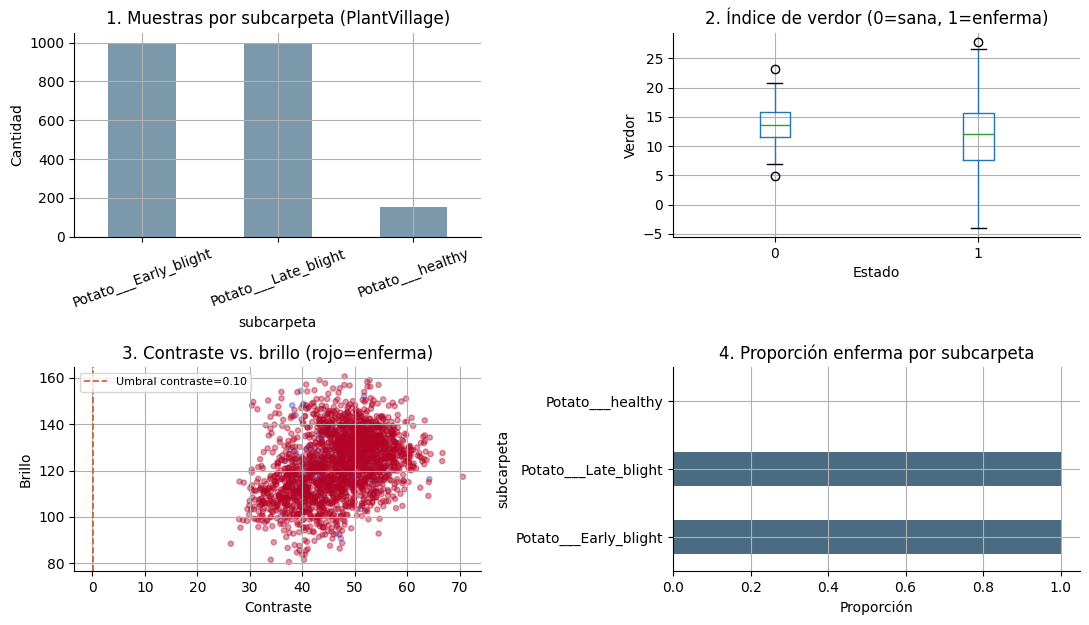

In [4]:
if "hoja_enferma" not in df_pv.columns:
    df_pv["hoja_enferma"] = (df_pv["etiqueta"] == "hoja_enferma").astype(int)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))

df_pv["subcarpeta"].value_counts().plot.bar(ax=axes[0, 0], color="#7c98ab", rot=20)
axes[0, 0].set_title("1. Muestras por subcarpeta (PlantVillage)")
axes[0, 0].set_ylabel("Cantidad")

df_pv.boxplot(column="verdor", by="hoja_enferma", ax=axes[0, 1])
axes[0, 1].set_title("2. Índice de verdor (0=sana, 1=enferma)")
axes[0, 1].set_xlabel("Estado")
axes[0, 1].set_ylabel("Verdor")
plt.suptitle("")

axes[1, 0].scatter(df_pv["contraste"], df_pv["brillo"], c=df_pv["hoja_enferma"], cmap="coolwarm", alpha=0.4, s=14)
axes[1, 0].axvline(0.10, color="#c85a32", linestyle="--", linewidth=1.2, label="Umbral contraste=0.10")
axes[1, 0].set_title("3. Contraste vs. brillo (rojo=enferma)")
axes[1, 0].set_xlabel("Contraste")
axes[1, 0].set_ylabel("Brillo")
axes[1, 0].legend(fontsize=8)

tasa_sub = df_pv.groupby("subcarpeta")["hoja_enferma"].mean()
tasa_sub.plot.barh(ax=axes[1, 1], color="#4a6b82")
axes[1, 1].set_title("4. Proporción enferma por subcarpeta")
axes[1, 1].set_xlabel("Proporción")

plt.tight_layout()
plt.show()


## 4. Hallazgo que cambia el enfoque e informe de calidad / linaje

In [5]:
import json, sys, sklearn

hallazgo = (
    "Las hojas enfermas presentan menor índice de verdor medio, pero las imágenes con bajo contraste (<0.10) "
    "o iluminación extrema concentran mayor ambigüedad visual y riesgo de error al transferir PlantVillage a campo. "
    "Cambia el enfoque: el modelo no debe decidir en solitario en fotos de baja calidad visual o duda alta; "
    "debe marcar esos casos para revisión humana."
)

informe = {
    "proyecto": "¿Hoja sana o enferma, y cuándo no fiarnos del modelo? Papas Canarias",
    "base_datos": "https://github.com/spMohanty/PlantVillage-Dataset",
    "origen_ejecucion": origen_pv if "origen_pv" in globals() else df_pv["origen"].iloc[0],
    "n_filas": int(len(df_pv)),
    "n_duplicados_md5": n_duplicados_md5,
    "n_bajo_contraste": int(bajo_contraste.sum()),
    "hallazgo_cambia_enfoque": hallazgo,
    "linaje": [
        "Fuente: PlantVillage-Dataset (spMohanty) o respaldo sintético SEMILLA=42 si no está descargado",
        "EDA: cálculo de brillo, contraste, verdor, hash MD5, detección de duplicados y casos de baja fiabilidad"
    ],
    "versiones": f"Python {sys.version.split()[0]}, numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}"
}
print(hallazgo)
print("\n" + json.dumps(informe, ensure_ascii=False, indent=2))


Las hojas enfermas presentan menor índice de verdor medio, pero las imágenes con bajo contraste (<0.10) o iluminación extrema concentran mayor ambigüedad visual y riesgo de error al transferir PlantVillage a campo. Cambia el enfoque: el modelo no debe decidir en solitario en fotos de baja calidad visual o duda alta; debe marcar esos casos para revisión humana.

{
  "proyecto": "¿Hoja sana o enferma, y cuándo no fiarnos del modelo? Papas Canarias",
  "base_datos": "https://github.com/spMohanty/PlantVillage-Dataset",
  "origen_ejecucion": "PlantVillage-Dataset (real)",
  "n_filas": 2152,
  "n_duplicados_md5": 0,
  "n_bajo_contraste": 0,
  "hallazgo_cambia_enfoque": "Las hojas enfermas presentan menor índice de verdor medio, pero las imágenes con bajo contraste (<0.10) o iluminación extrema concentran mayor ambigüedad visual y riesgo de error al transferir PlantVillage a campo. Cambia el enfoque: el modelo no debe decidir en solitario en fotos de baja calidad visual o duda alta; debe marc